# 03 - Quantile Methods

Instead of predicting the mean and bolting on a symmetric band, predict the 5th and 95th
**percentiles** directly with the pinball (quantile) loss. Because each bound is its own
fit, the interval **width can vary** with the input - the thing the normal interval cannot do.

In [1]:
import sys
from pathlib import Path

_root = Path.cwd()
while not (_root / "pyproject.toml").exists() and _root != _root.parent:
    _root = _root.parent
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.artifacts import save_fig, save_json

plt.rcParams["figure.figsize"] = (7, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
NOMINAL = 0.90
SEED = 42

In [2]:
from src.datasets.synthetic import make_synthetic
from src.intervals.normal import NormalInterval
from src.intervals.quantile_regression import QuantileRegressor
from src.intervals.gbm_quantile import GBMQuantileInterval
from src.evaluation.coverage import coverage
from src.evaluation.conditional import conditional_coverage
from src.evaluation.width import mean_width
from src.visualisation import plot_intervals

d = make_synthetic("heteroscedastic", 6000, SEED)
x_tr, y_tr, x_te, y_te = d.x[:4000], d.y[:4000], d.x[4000:], d.y[4000:]

methods = {
    "normal": NormalInterval(coverage=NOMINAL),
    "quantile_regression": QuantileRegressor(quantiles=(0.05, 0.95), n_iter=2000),
    "gbm_quantile": GBMQuantileInterval(quantiles=(0.05, 0.95), n_estimators=200),
}
results = {}
for name, m in methods.items():
    m.fit(x_tr, y_tr)
    lo, hi = m.predict_interval(x_te)
    cond = conditional_coverage(y_te, lo, hi, by=x_te.ravel(), n_bins=8)
    results[name] = {"coverage": float(coverage(y_te, lo, hi)),
                     "mean_width": float(mean_width(lo, hi)),
                     "conditional": cond, "lo": lo, "hi": hi}
    print(f"{name:20s} cov={results[name]['coverage']:.3f}  width={results[name]['mean_width']:.2f}")

normal               cov=0.881  width=15.01
quantile_regression  cov=0.931  width=15.12


gbm_quantile         cov=0.900  width=13.65


## Quantile regression recovers a width that grows with the volatile region

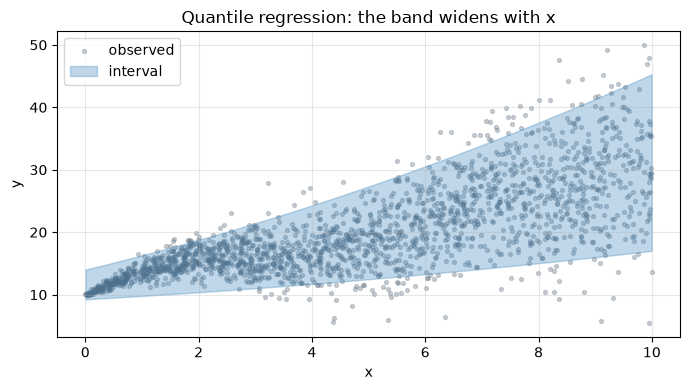

In [3]:
lo, hi = results["quantile_regression"]["lo"], results["quantile_regression"]["hi"]
fig = plot_intervals(x_te, y_te, lo, hi, title="Quantile regression: the band widens with x")
save_fig(fig, "03_quantile_regression_band")
plt.show()

## Conditional coverage: both quantile methods beat the normal interval

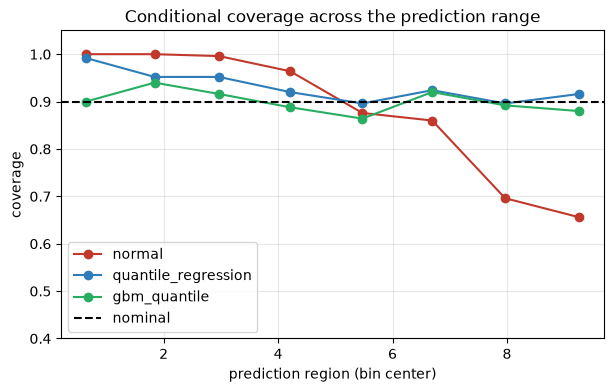

In [4]:
palette = {"normal": "#C0392B", "quantile_regression": "#2E7DB8", "gbm_quantile": "#27AE60"}
fig, ax = plt.subplots()
for name, color in palette.items():
    c = results[name]["conditional"]
    ax.plot(c["center"], c["coverage"], marker="o", color=color, label=name)
ax.axhline(NOMINAL, color="black", ls="--", label="nominal")
ax.set_ylim(0.4, 1.05); ax.set_xlabel("prediction region (bin center)"); ax.set_ylabel("coverage")
ax.legend(); ax.set_title("Conditional coverage across the prediction range")
save_fig(fig, "03_conditional_comparison")
plt.show()

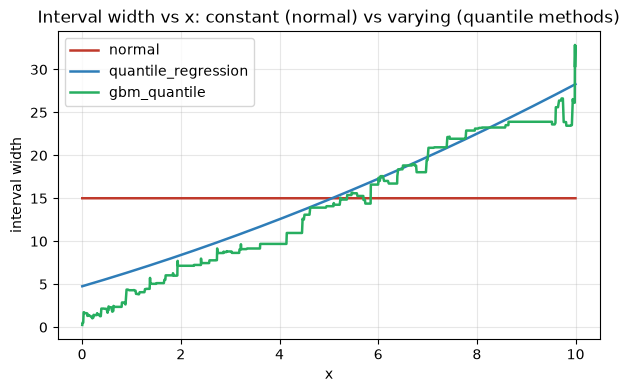

In [5]:
order = np.argsort(x_te.ravel())
xs = x_te.ravel()[order]
fig, ax = plt.subplots()
for name, color in palette.items():
    w = (results[name]["hi"] - results[name]["lo"])[order]
    ax.plot(xs, w, color=color, lw=1.8, label=name)
ax.set_xlabel("x"); ax.set_ylabel("interval width"); ax.legend()
ax.set_title("Interval width vs x: constant (normal) vs varying (quantile methods)")
save_fig(fig, "03_width_vs_x")
plt.show()

In [6]:
save_json("03_quantile_methods", {
    "nominal_coverage": NOMINAL,
    "methods": {name: {"coverage": results[name]["coverage"],
                       "mean_width": results[name]["mean_width"],
                       "conditional": results[name]["conditional"].to_dict(orient="records")}
                for name in methods},
})

PosixPath('/workspaces/prediction_intervals_arena/outputs/data/03_quantile_methods.json')

**Honest limitation:** quantile methods retrain the model to target quantiles and still
carry **no coverage guarantee** - they can miss the nominal rate. That is what conformal
prediction fixes.